In [4]:
"""Run before code to install libraries"""
!pip install numpy scipy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 29.8 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 45.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 44.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 42.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 35.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 44.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [matplotlib]9 [matplotlib]


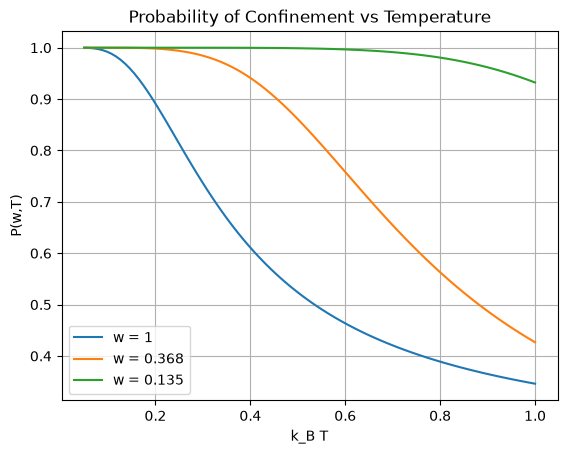

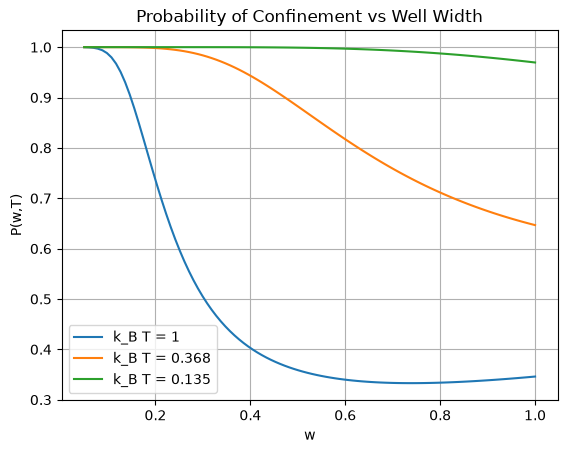

In [10]:
"""Problem 1"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad 
"""I had to use the github below for help w this"""
"""https://scipy.github.io/devdocs/reference/generated/scipy.integrate.quad.html """

def get_probability(w, kbT):
    # Define the integrand inside the function so we aren't passing around as much data
    def integrand(x):
        return np.exp((1 / (w * kbT)) * np.exp(-(x**2) / (2 * w**2)))
    
    numerator, err_num = quad(integrand, -w, w)
    denominator, err_den = quad(integrand, -5, 5)
    
    probability = numerator / denominator
    return probability

# Part 1b
kbT_values = np.linspace(np.exp(-3), 1, 100)
w_values_to_test = [1, np.exp(-1), np.exp(-2)]

plt.figure()
for w in w_values_to_test:
    p_results = []
    # Loop through each temperature and calculate the probability one by one
    for T in kbT_values:
        p = get_probability(w, T)
        p_results.append(p)
        
    plt.plot(kbT_values, p_results, label="w = " + str(round(w, 3)))

plt.xlabel("k_B T")
plt.ylabel("P(w,T)")
plt.title("Probability of Confinement vs Temperature")
plt.legend()
plt.grid(True)
plt.show()

# Part 1c
w_values = np.linspace(np.exp(-3), 1, 100)
kbT_values_to_test = [1, np.exp(-1), np.exp(-2)]

plt.figure()
for T in kbT_values_to_test:
    p_results = []
    # Loop through each width and calculate the probability one by one
    for w in w_values:
        p = get_probability(w, T)
        p_results.append(p)
        
    plt.plot(w_values, p_results, label="k_B T = " + str(round(T, 3)))

plt.xlabel("w")
plt.ylabel("P(w,T)")
plt.title("Probability of Confinement vs Well Width")
plt.legend()
plt.grid(True)
plt.show()

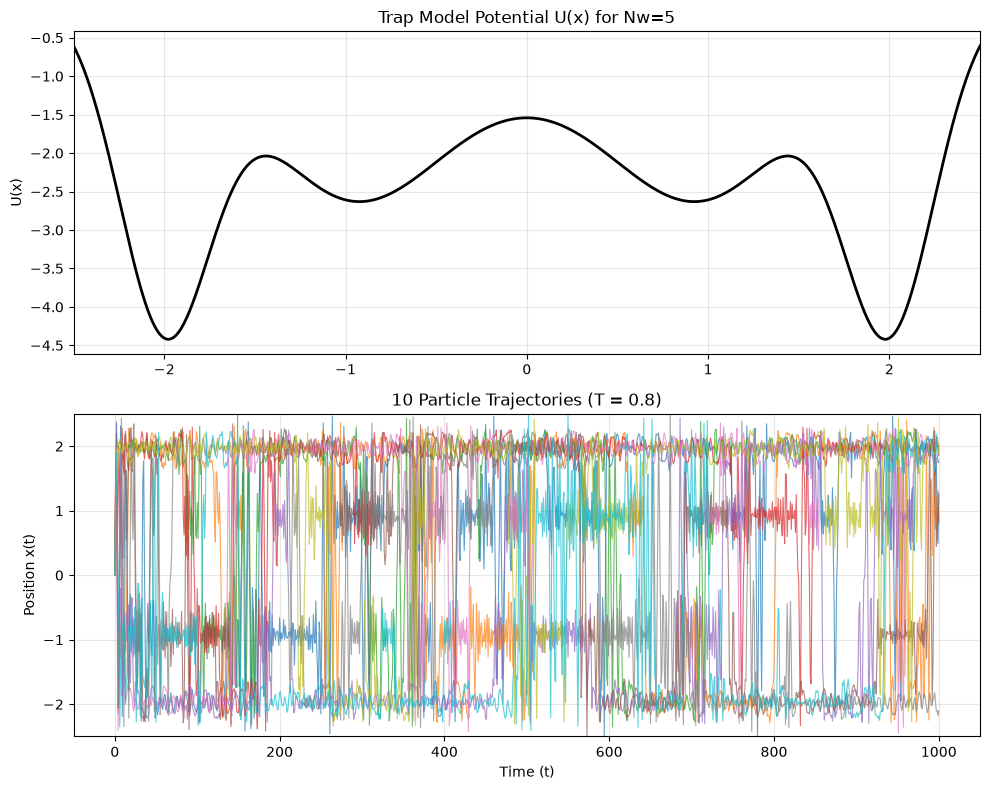

In [ ]:
"""Problem 2"""
import math
import random
import matplotlib.pyplot as plt

# Parameters and Initialization
Nw = 5                  # Number of wells
L = float(Nw)           # System size

# Set up Dw * Ww = 1.0 for equal area
Dw = [4.0, 2.0, 1.0, 2.0, 4.0]
Ww = [0.25, 0.5, 1.0, 0.5, 0.25]
xw = [-2.0, -1.0, 0.0, 1.0, 2.0]

Nsteps = 400000         # Total integration steps
Nevery = 400            #Data sampling frequency
Ttarg = 0.8             # Target temperature
lam = 0.1               #Friction coefficient
dt = 0.0025             # Timestep
num_trajectories = 10   # Independent runs

def get_force_and_potential(x):
    f = 0.0
    U = 0.0
    for i in range(Nw):
        dx = x - xw[i]
        exp_term = math.exp(-(dx * dx) / (2.0 * Ww[i] * Ww[i]))
        U += -Dw[i] * exp_term
        # Analytical derivative
        f += -Dw[i] * (dx / (Ww[i] * Ww[i])) * exp_term
    return f, U

# Simulation Loop
all_t = []
all_x = []

for run in range(num_trajectories):
    x = 0.0                     # Start in center well
    v = math.sqrt(Ttarg)        # Initial velocity
    
    t_vals = []
    x_vals = []
    
    for step in range(Nsteps + 1):
        if step % Nevery == 0:
            t_vals.append(step * dt)
            x_vals.append(x)
            
        # First part of leapfrog integration
        f, U = get_force_and_potential(x)
        f -= lam * v
        
        # Langevin random force
        rand_val = random.uniform(0.0, 1.0) - 0.5
        f += math.sqrt(24.0 * lam * Ttarg / (dt / 2.0)) * rand_val
        v += f * (dt / 2.0)
        
        # Reflecting boundary conditions
        if x + v * dt > L / 2.0:
            v *= -1.0
            # print(f"{v})
        if x + v * dt < -L / 2.0:
            v *= -1.0
            
        x += v * dt
        
        # This starts the second part of leapfrog integration
        f, U = get_force_and_potential(x)
        f -= lam * v
        
        rand_val = random.uniform(0.0, 1.0) - 0.5
        f += math.sqrt(24.0 * lam * Ttarg / (dt / 2.0)) * rand_val
        v += f * (dt / 2.0)
        
    all_t.append(t_vals)
    all_x.append(x_vals)

# Graphing
x_pot = []
U_pot = []
for i in range(1001):
    x_val = -L/2.0 + (L/1000.0) * i
    _, U_val = get_force_and_potential(x_val)
    x_pot.append(x_val)
    U_pot.append(U_val)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=False)

ax1.plot(x_pot, U_pot, 'k', linewidth=2)
ax1.set_title(f'Trap Model Potential U(x) for Nw={Nw}')
ax1.set_ylabel('U(x)')
ax1.set_xlim(-L/2, L/2)
ax1.grid(True, alpha=0.3)

for i in range(num_trajectories):
    ax2.plot(all_t[i], all_x[i], linewidth=0.8, alpha=0.7)
ax2.set_title(f'10 Particle Trajectories (T = {Ttarg})')
ax2.set_xlabel('Time (t)')
ax2.set_ylabel('Position x(t)')
ax2.set_ylim(-L/2, L/2)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()